# NN_L2_vanishing

**Gradient norm per layer at initialisation in a 10-layer MLP on one batch of real California data: sigmoid and tanh with Xavier initialisation, ReLU with He and with too small weights (mean of 5 seeds).**

Neural Networks and Deep Learning (NN), Lecture 2 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L2/NN_L2_vanishing/NN_L2_vanishing.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

Lecture 2 of *Neural Networks and Deep Learning*: the chart `vanishing` of the slides, recomputed from the public data. Numbers printed with `show()` are the ones on the slide.

sigmoid, Xavier init.: first-layer gradient norm = 8.48e-07   [vanish.sig.first]
tanh, Xavier init.: first-layer gradient norm = 1.0   [vanish.tanh.first]
ReLU, He init.: first-layer gradient norm = 3.07   [vanish.relu_he.first]
ReLU, N(0, 0.01²) init.: first-layer gradient norm = 6.9e-13   [vanish.relu_small.first]


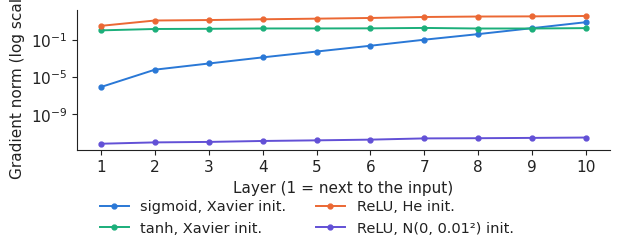

In [3]:
import torch, torch.nn as nn
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import train_test_split
from scipy import stats
torch.set_num_threads(1)
SEED = 20261108
ca = pd.read_csv(DATA + 'california_housing.csv')
feat = [c for c in ca.columns if c != 'MedHouseVal_100k_usd']
Xc = ca[feat].values.astype(np.float32); yc = ca['MedHouseVal_100k_usd'].values.astype(np.float32)
i_tr, i_te = train_test_split(np.arange(len(ca)), test_size=0.2, random_state=SEED)
i_tr, i_va = train_test_split(i_tr, test_size=0.25, random_state=SEED)
mu, sd = Xc[i_tr].mean(0), Xc[i_tr].std(0); Z = (Xc - mu) / sd
Xtr, Xva, Xte, ytr, yva, yte = Z[i_tr], Z[i_va], Z[i_te], yc[i_tr], yc[i_va], yc[i_te]
lin = LinearRegression().fit(Xtr, ytr)
mse_lin_val = float(np.mean((lin.predict(Xva) - yva) ** 2)); mse_lin_te = float(np.mean((lin.predict(Xte) - yte) ** 2))

def make_mlp(d, hidden=(64, 64), act=nn.ReLU):
    layers, k = [], d
    for h in hidden:
        layers += [nn.Linear(k, h), act()]; k = h
    return nn.Sequential(*layers, nn.Linear(k, 1))

def make_opt(name, params, lr):
    return {'sgd': lambda: torch.optim.SGD(params, lr=lr), 'momentum': lambda: torch.optim.SGD(params, lr=lr, momentum=0.9),
            'rmsprop': lambda: torch.optim.RMSprop(params, lr=lr, alpha=0.99), 'adam': lambda: torch.optim.Adam(params, lr=lr),
            'adamw': lambda: torch.optim.AdamW(params, lr=lr, weight_decay=1e-2)}[name]()

def run_reg(opt_name, lr, seed=0, epochs=60, bs=128, sched=None):
    torch.manual_seed(SEED + seed); rng = np.random.default_rng(SEED + seed)
    m = make_mlp(Xtr.shape[1]); opt = make_opt(opt_name, m.parameters(), lr)
    spe = int(np.ceil(len(Xtr) / bs)); total = epochs * spe
    sch = {'step': lambda: torch.optim.lr_scheduler.StepLR(opt, step_size=20 * spe, gamma=0.1),
           'cosine': lambda: torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=total),
           'onecycle': lambda: torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=total, pct_start=0.3)}.get(sched, lambda: None)()
    Xt, yt = torch.tensor(Xtr), torch.tensor(ytr).view(-1, 1); Xv, yv = torch.tensor(Xva), torch.tensor(yva).view(-1, 1)
    val, lrs = [], []
    for ep in range(epochs):
        m.train(); idx = rng.permutation(len(Xt))
        for i in range(0, len(idx), bs):
            b = idx[i:i + bs]; opt.zero_grad(); nn.MSELoss()(m(Xt[b]), yt[b]).backward(); opt.step()
            lrs.append(opt.param_groups[0]['lr'])
            if sch is not None:
                sch.step()
        m.eval()
        with torch.no_grad():
            v = float(nn.MSELoss()(m(Xv), yv)); val.append(v if np.isfinite(v) else 1e9)
    with torch.no_grad():
        te = float(nn.MSELoss()(m(torch.tensor(Xte)), torch.tensor(yte).view(-1, 1)))
    return {'val': val, 'test': te if np.isfinite(te) else 1e9, 'lr': lrs[::spe]}
def grad_norms(act, init, depth=10, width=64, seed=0):
    torch.manual_seed(SEED + seed); layers, k, lins = [], Xtr.shape[1], []
    for _ in range(depth):
        l = nn.Linear(k, width); lins.append(l); layers += [l, act()]; k = width
    last = nn.Linear(k, 1); lins.append(last); m = nn.Sequential(*layers, last)
    for l in lins:
        {'xavier': lambda w: nn.init.xavier_normal_(w), 'he': lambda w: nn.init.kaiming_normal_(w, nonlinearity='relu'),
         'small': lambda w: nn.init.normal_(w, 0, 0.01)}[init](l.weight); nn.init.zeros_(l.bias)
    nn.MSELoss()(m(torch.tensor(Xtr[:512])), torch.tensor(ytr[:512]).view(-1, 1)).backward()
    return [float(l.weight.grad.norm()) for l in lins[:-1]]
VG = {'sig': (nn.Sigmoid, 'xavier', 'sigmoid, Xavier init.'), 'tanh': (nn.Tanh, 'xavier', 'tanh, Xavier init.'),
      'relu_he': (nn.ReLU, 'he', 'ReLU, He init.'), 'relu_small': (nn.ReLU, 'small', 'ReLU, N(0, 0.01²) init.')}
fig, ax = plt.subplots(figsize=(6.4, 2.6))
for k, (a, i, nm), c in zip(VG, VG.values(), (PAL['data'], PAL['benchmark'], PAL['model'], '#6250d6')):
    gn = np.mean([grad_norms(a, i, seed=s) for s in range(5)], axis=0)
    show(f'vanish.{k}.first', f'{nm}: first-layer gradient norm', float(f'{gn[0]:.2e}'))
    ax.plot(range(1, 11), gn, 'o-', ms=3.5, color=c, label=nm)
ax.set_yscale('log'); ax.set_xticks(range(1, 11)); ax.set_xlabel('Layer (1 = next to the input)'); ax.set_ylabel('Gradient norm (log scale)')
legend_bottom(fig, ncol=2); fig.tight_layout(rect=(0, 0.14, 1, 1))
fig.savefig('vanishing.png', dpi=200, transparent=True, bbox_inches='tight'); plt.show()